![Banner](images/09_distributed_spatial_datas.png)

# Flow Direction and Accumulation on Large DEMs

Drainage analysis turns an elevation model into rivers and catchments: which way water flows from
each cell, how much area drains through it, and where the streams are. It is a standard first step
for flood mapping, erosion and water quality models. It is also the clearest example in this
chapter of an analysis that does not split into chunks: the water arriving at a river mouth comes
from cells hundreds of kilometres upstream. This notebook computes D8 flow direction for the 262
million pixel Great Plains DEM chunk by chunk on CPU and GPU, measures how far the in-memory
depression filling and flow accumulation of `geolattice.distributed.hydrology` scale, runs the
full DEM through WhiteboxTools, and maps the streams and the largest catchment of a Kansas basin.

## Overview

### The D8 model

Each cell drains to the steepest downhill of its 8 neighbours (**flow direction**). Following those
pointers from cell to cell traces flow paths; counting how many cells' paths pass through a cell
gives its **flow accumulation** (contributing area). Cells whose accumulation exceeds a threshold
form the **stream network**, and the cells that drain to a chosen outlet form its **catchment**.

### Local and global steps

| Step | Information needed | Chunking |
|---|---|---|
| Flow direction | the 8 neighbours | local: chunks plus a 1 pixel halo, exact |
| Depression filling | the lowest outlet of every depression, possibly far away | global: a depression can span many chunks |
| Flow accumulation | every cell upstream | global: one cell's answer depends on cells across the DEM |
| Streams, catchments | accumulation and flow paths | global |

Real DEMs contain **depressions** (pits) with no downhill neighbour: real closed basins, errors,
and places where a road embankment hides a culvert. Water would stop there, so depressions are
**filled** (raised to their spill level; priority-flood, Barnes et al. 2014) or **breached** (a
channel is cut through the barrier) before accumulation.

### Strategies for DEMs that are too large

1. **In memory**, when it fits: simplest and exact.
2. **Tile by watershed**: cut the DEM along drainage divides (from a coarse DEM or a basin
   dataset such as HydroBASINS), so no flow crosses a tile edge, and process each basin alone.
3. **Coarsen**: run on a 270 m or 1 km DEM when the analysis allows.
4. **Specialised out-of-core tools**: WhiteboxTools (multithreaded Rust), TauDEM (MPI), RichDEM,
   or parallel priority-flood algorithms that exchange information between tiles (Barnes 2016).

## Hydrology with GeoLattice

| Function | Runs | Chunked |
|---|---|---|
| `pdist.hydrology.flow_direction(dem)` | CPU or GPU | yes: 1 pixel halo, NaN outside the DEM; codes 0 to 7 (N, NE, E, SE, S, SW, W, NW), -1 where no neighbour is lower |
| `pdist.hydrology.fill_depressions(dem)` | CPU, in memory | no: loads lazy input whole |
| `pdist.hydrology.flow_accumulation(dem, filled=, weights=)` | CPU, in memory | no: one sparse linear system `(I - A) acc = w` |
| `geolattice.whitebox` | WhiteboxTools, out of process | the tool manages memory and threads |

### Learning objectives

1. Separate local from global hydrological operations and explain why accumulation cannot be
   chunked exactly.
2. Compute D8 flow direction for a 262 million pixel DEM on CPU and GPU, and confirm that the
   chunked result equals the whole-array result.
3. Measure how time and memory of in-memory filling and accumulation grow with DEM size, and
   extrapolate to the full DEM.
4. Run WhiteboxTools on the full DEM and compare it with GeoLattice on a basin.
5. Extract streams and the largest catchment of a basin.

### Data

| Dataset | Content |
|---|---|
| Great Plains elevation | 90 m DEM, 17,196 x 15,245 pixels, EPSG:5070 |

### Contents

- Setup
- D8 flow direction, chunked, on CPU and GPU
- How far does in-memory filling and accumulation scale?
- The full DEM with WhiteboxTools
- Streams and catchments of a Kansas basin
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import shutil  # remove scratch files
from scipy.optimize import curve_fit  # power-law fits
from geolattice.rsense.lidar import terrain as tr  # whole-array reference implementations
from geolattice.rsense.lidar.terrain import _receivers  # D8 receiver of every cell
import whitebox  # WhiteboxTools
HY = (OUT / "hydrology").resolve()  # scratch folder (absolute: WhiteboxTools runs in its own directory)
HY.mkdir(parents=True, exist_ok=True)  # create it


def sync():  # wait for queued GPU work so timings are real
    if caps["gpus"]:  # only with a GPU
        import cupy as cp  # GPU arrays
        cp.cuda.Device().synchronize()  # block until done

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## D8 flow direction, chunked, on CPU and GPU

Flow direction needs only each cell's 8 neighbours, so it runs chunk by chunk with a 1 pixel halo.
Outside the DEM (and in no-data holes) the halo holds NaN, so no cell drains off the edge by
accident.

In [2]:
dem = dd.gp_raster("elev").compute()  # 262 million pixels in memory
t = {}  # timings
for c in (["cpu", "gpu"] if caps["gpus"] else ["cpu"]):  # both targets
    pdist.hydrology.flow_direction(dem, compute=c); sync()  # warm-up
    t0 = time.perf_counter(); fd = pdist.hydrology.flow_direction(dem, compute=c); sync(); t[f"chunked, {c}"] = time.perf_counter() - t0  # time
t0 = time.perf_counter(); fd_ref = tr.flow_direction(dem); t["whole array, NumPy, one core"] = time.perf_counter() - t0  # reference
print(pd.Series(t, name="seconds").round(2).to_string())  # timings
print("chunked equals whole-array result:", bool((fd.values == np.asarray(fd_ref)).all()))  # exact match
codes = pd.Series(fd.values.ravel()).value_counts().sort_index()  # cells per direction
names = {-1: "none (pit, flat or no data)", 0: "N", 1: "NE", 2: "E", 3: "SE", 4: "S", 5: "SW", 6: "W", 7: "NW"}  # code names
valid = int(np.isfinite(dem.values).sum())  # cells with data
pits = int(((fd.values == -1) & np.isfinite(dem.values)).sum())  # cells with data and no lower neighbour
print(f"cells with data: {valid:,}; with no lower neighbour: {pits:,} ({pits / valid:.1%})")  # depressions and flats
codes.rename(index=names).to_frame("cells")  # table

chunked, cpu                     8.72
chunked, gpu                     1.01
whole array, NumPy, one core    22.73
chunked equals whole-array result: True


cells with data: 123,456,899; with no lower neighbour: 12,344,339 (10.0%)


,cells
"none (pit, flat or no data)",151040460
N,18297819
NE,10969291
E,19814376
SE,10926159
S,17640767
SW,9481948
W,15402723
NW,8579477


The chunked result equals the whole-array result cell for cell, on both targets, and the GPU
was about eight times faster than the CPU chunks. One cell in ten with data has no lower
neighbour: pits, flats and cells next to no-data holes, which is why the next step fills them.
The four cardinal directions are more common than the diagonals, because a diagonal neighbour is
1.4 times farther away and so needs a larger drop to be the steepest; east is the most common, the
regional slope of the Great Plains from the Rockies towards the Missouri and Mississippi.

## How far does in-memory filling and accumulation scale?

Filling and accumulation are global. GeoLattice computes them in memory: priority-flood filling
(a heap-based loop, one cell at a time in Python) and accumulation as a topological sweep down the
flow paths. (An earlier version solved accumulation as one sparse linear system with SciPy's
general LU solver; while this notebook was written it ran out of memory on the 4096 x 4096 basin
below, so it was replaced by the sweep, which gives identical results with memory that grows
linearly.) The cells
below time both on square windows of growing size in central Kansas and record the peak memory,
then fit power laws and extrapolate to the full DEM.

In [3]:
r0, c0 = 8000, 9000  # top-left corner of the windows, central Kansas
rows = []  # one row per window size
for n in [256, 512, 1024, 2048]:  # window sides (4096 follows in the basin section)
    w = dem[r0:r0 + n, c0:c0 + n].rio.interpolate_na()  # fill the scattered no-data holes from their neighbours
    with dd.PeakMemory(0.02) as pm:  # watch memory
        t0 = time.perf_counter(); filled = pdist.hydrology.fill_depressions(w); t_fill = time.perf_counter() - t0  # priority flood
        t0 = time.perf_counter(); acc = pdist.hydrology.flow_accumulation(filled, filled=True); t_acc = time.perf_counter() - t0  # sparse solve
    rows.append({"cells": n * n, "fill (s)": t_fill, "accumulate (s)": t_acc, "extra memory (GB)": pm.peak_gb - pm.start_gb})  # row
scal = pd.DataFrame(rows).set_index("cells")  # table
scal.round(3)  # show

,fill (s),accumulate (s),extra memory (GB)
cells,,,
65536,0.241,0.017,0.000
262144,1.065,0.060,0.001
1048576,4.502,0.258,0.009
4194304,19.032,1.462,0.182


In [4]:
power = lambda n, a, b: a * n ** b  # time or memory = a n^b
N = dem.size  # 262 million cells
fits = {}  # fitted exponents and extrapolations
for col in ["fill (s)", "accumulate (s)"]:  # the two run times
    (a, b), _ = curve_fit(power, scal.index.values.astype(float), scal[col].values, p0=[1e-6, 1.0], maxfev=20000)  # fit
    fits[col] = {"exponent": b, "full DEM (extrapolated)": power(N, a, b)}  # extrapolate
fits = pd.DataFrame(fits).T  # table
per_cell = scal["extra memory (GB)"].iloc[-1] * 1e9 / scal.index[-1]  # bytes per cell at the largest window
print(f"full DEM: {N / 1e6:.0f} million cells, {dd.gb(dem.nbytes)} as float32; memory grows linearly, "  # size
      f"about {per_cell:.0f} bytes per cell, so roughly {per_cell * N / 1e9:.0f} GB for the full DEM")  # memory estimate
fits.round(2)  # show

full DEM: 262 million cells, 1.05 GB as float32; memory grows linearly, about 43 bytes per cell, so roughly 11 GB for the full DEM


,exponent,full DEM (extrapolated)
fill (s),1.04,1404.38
accumulate (s),1.24,243.46


Both run times grow close to linearly with the number of cells, and so does memory, at a few
tens of bytes per cell. Extrapolated to all 262 million cells, accumulation would take a few
minutes and the memory would fit this machine easily; filling is the slow part, at more than
twenty minutes, because the priority-flood loop visits one cell at a time in Python. The full
Great Plains DEM is therefore within reach of the in-memory route on this machine, but slowly,
and a DEM ten times larger would not fit. For the whole region, a compiled tool is the better
choice.

## The full DEM with WhiteboxTools

WhiteboxTools is a compiled, multithreaded program; `geolattice.whitebox` runs it on files. The
full DEM is written to a GeoTIFF, filled (Wang and Liu's fast priority-flood variant), and
accumulated with D8 (output in cells).

In [5]:
wbt = whitebox.WhiteboxTools(); wbt.set_verbose_mode(False)  # quiet runs
src = HY / "elev.tif"  # input
dem.rio.to_raster(src, tiled=True, compress="DEFLATE")  # write the in-memory DEM
steps = {}  # timings
t0 = time.perf_counter(); wbt.fill_depressions_wang_and_liu(str(src), str(HY / "filled.tif")); steps["fill depressions"] = time.perf_counter() - t0  # fill
t0 = time.perf_counter(); wbt.d8_flow_accumulation(str(HY / "filled.tif"), str(HY / "acc.tif"), out_type="cells"); steps["D8 flow accumulation"] = time.perf_counter() - t0  # accumulate
print(pd.Series(steps, name="seconds").round(1).to_string())  # timings
acc_full = pdist.read_raster(HY / "acc.tif", chunks={"y": 2048, "x": 2048})  # lazy result
print(f"largest accumulation: {float(acc_full.max()):,.0f} cells = {float(acc_full.max()) * 0.0081:,.0f} km2")  # biggest basin

fill depressions        50.1
D8 flow accumulation    10.5


largest accumulation: 12,717,194 cells = 103,009 km2


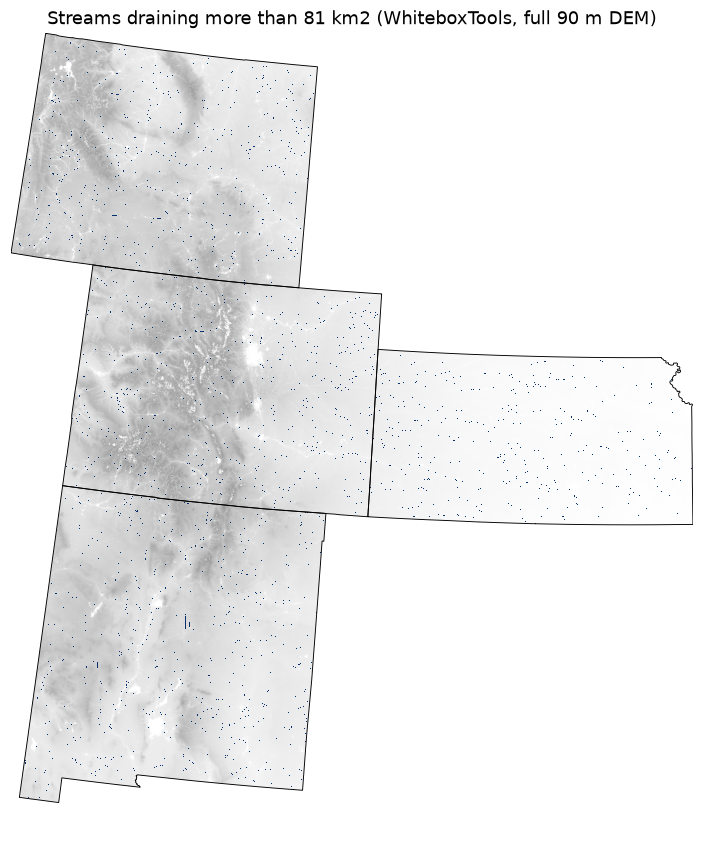

In [6]:
streams = (acc_full >= 10_000)  # cells draining at least 81 km2
q = streams[::4, ::4].compute()  # every 4th cell for plotting
fig, ax = plt.subplots(figsize=(8, 8))  # one map
ax.imshow(dd.quicklook(dd.gp_raster("elev"), 4), cmap="Greys", extent=dd.extent(q), alpha=0.5)  # elevation backdrop
ax.imshow(np.where(q, 1.0, np.nan), cmap="Blues_r", extent=dd.extent(q), interpolation="nearest")  # streams
dd.gp_states().boundary.plot(ax=ax, color="k", lw=0.6)  # states
ax.set_title("Streams draining more than 81 km2 (WhiteboxTools, full 90 m DEM)"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw

WhiteboxTools processed all 262 million cells in about a minute: the out-of-core and
multithreaded route for DEMs too large for the in-memory functions. The stream network shows the
Platte, Arkansas, Smoky Hill, Republican and Kansas rivers and the Rio Grande. Breaks in some
rivers come from the DEM's no-data holes, where the filling treats every hole as an outlet.

## Streams and catchments of a Kansas basin

GeoLattice's in-memory functions handle a 4096 x 4096 window (369 x 369 km) of central Kansas
in about a minute and a half, and the
results can be compared with WhiteboxTools on the same window. Every cell then gets the outlet
its flow path ends at (by pointer jumping along the D8 receivers), and the cells sharing the
outlet with the largest accumulation form the window's largest catchment.

In [7]:
w = dem[r0:r0 + 4096, c0:c0 + 4096].rio.interpolate_na()  # the window, holes filled
t0 = time.perf_counter()  # start
zf = pdist.hydrology.fill_depressions(w)  # fill
fdw = pdist.hydrology.flow_direction(zf, compute="cpu")  # flow direction of the filled DEM
acc = pdist.hydrology.flow_accumulation(zf, filled=True)  # accumulation
print(f"GeoLattice, 17 million cells in memory: {time.perf_counter() - t0:.0f} s")  # time
w.rio.to_raster(HY / "win.tif")  # the same window for WhiteboxTools
wbt.fill_depressions_wang_and_liu(str(HY / "win.tif"), str(HY / "win_f.tif"))  # fill
wbt.d8_flow_accumulation(str(HY / "win_f.tif"), str(HY / "win_acc.tif"), out_type="cells")  # accumulate
acc_wb = pdist.read_raster(HY / "win_acc.tif").compute()  # Whitebox result
s_gl, s_wb = np.asarray(acc) >= 1000, acc_wb.values >= 1000  # streams draining 8.1 km2
agree = (s_gl & s_wb).sum() / (s_gl | s_wb).sum()  # overlap of the two stream networks
print(f"stream cells: GeoLattice {s_gl.sum():,}, WhiteboxTools {s_wb.sum():,}; overlap (intersection / union) {agree:.1%}")  # comparison

GeoLattice, 17 million cells in memory: 90 s


stream cells: GeoLattice 680,482, WhiteboxTools 680,894; overlap (intersection / union) 98.9%


largest catchment in the window: 5,471,197 cells = 44,317 km2


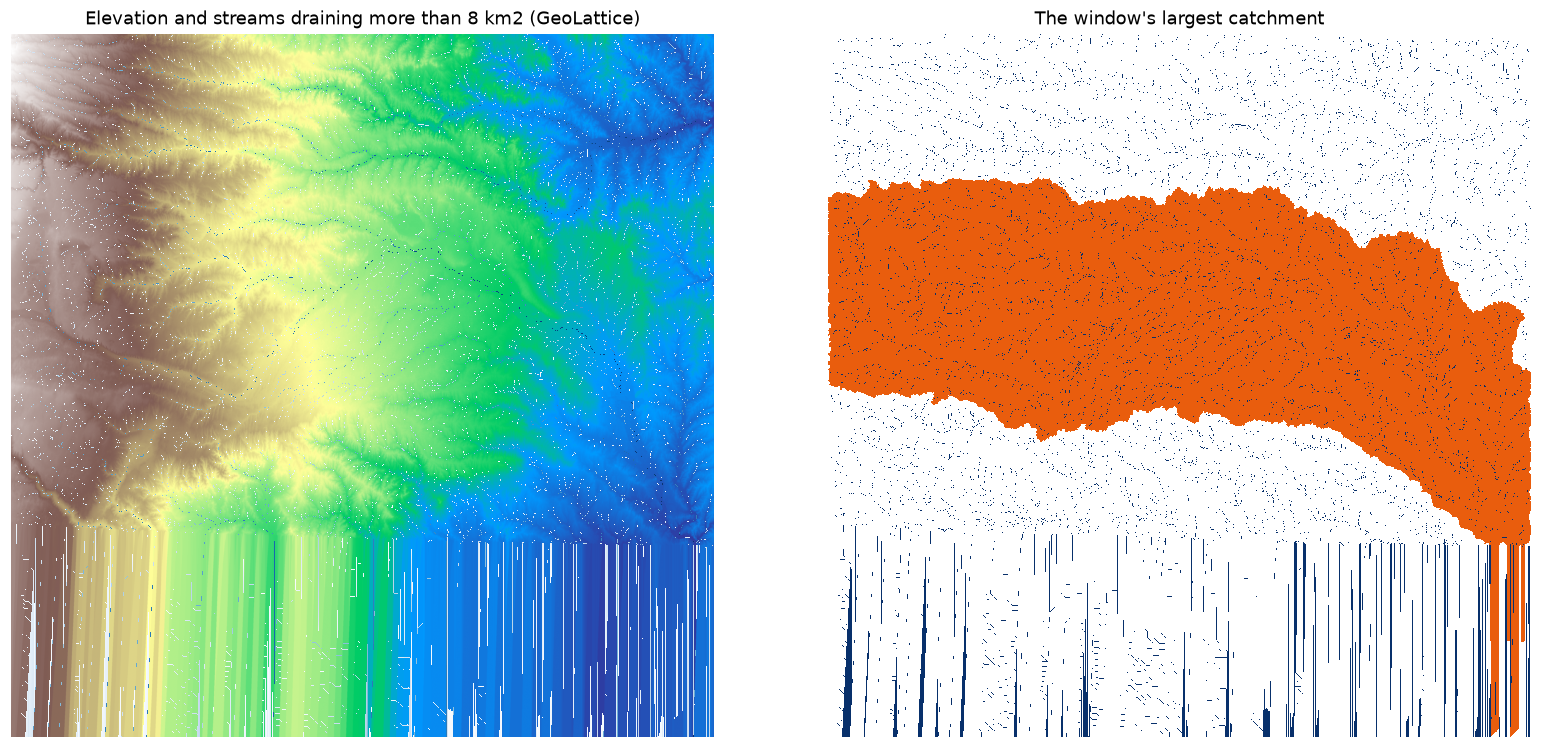

In [8]:
rec = _receivers(np.asarray(fdw.values))  # receiver of every cell (-1 at outlets)
idx = np.arange(rec.size)  # cell numbers
tgt = np.where(rec < 0, idx, rec)  # one step downstream (outlets point to themselves)
for _ in range(64):  # pointer jumping: each round doubles the distance followed
    nxt = tgt[tgt]  # two steps
    if np.array_equal(nxt, tgt):  # every cell has reached its outlet
        break
    tgt = nxt  # continue
acc_v = np.asarray(acc).ravel()  # accumulation as a vector
main = tgt[np.argmax(acc_v)]  # outlet of the cell with the largest accumulation
catch = (tgt == main).reshape(acc.shape)  # its catchment
print(f"largest catchment in the window: {catch.sum():,} cells = {catch.sum() * 0.0081:,.0f} km2")  # area
fig, ax = plt.subplots(1, 2, figsize=(15, 7))  # two maps
ext = dd.extent(w)  # extent
ax[0].imshow(w, cmap="terrain", extent=ext)  # elevation
ax[0].imshow(np.where(np.asarray(acc) >= 1000, np.log10(np.asarray(acc)), np.nan), cmap="Blues", extent=ext, interpolation="nearest")  # streams
ax[0].set_title("Elevation and streams draining more than 8 km2 (GeoLattice)")  # title
ax[1].imshow(np.where(catch, 1, np.nan), cmap="Oranges", vmin=0, vmax=1.5, extent=ext, interpolation="nearest")  # catchment
ax[1].imshow(np.where(s_gl, 1, np.nan), cmap="Blues_r", extent=ext, interpolation="nearest")  # streams on top
ax[1].set_title("The window's largest catchment"); [a.set_axis_off() for a in ax]  # labels
plt.tight_layout(); plt.show()  # draw

In [9]:
shutil.rmtree(HY)  # remove the scratch files

GeoLattice and WhiteboxTools give nearly the same stream network on the window. The remaining
differences come from flats: the two programs give filled flats slightly different gradients
(GeoLattice an `epsilon` of 10^-4 m per step, Wang and Liu's method none), so flow across large
flat areas can take different routes. The largest catchment in the window ends where its river
leaves the window. That is the practical lesson of the section: a catchment cut by a tile edge is
incomplete, which is why large DEMs are tiled along drainage divides, not along rows and columns.

## Summary and exercises

- Flow direction is local and was computed for 262 million cells chunk by chunk, identical to
  the whole-array result, on CPU and GPU.
- Depression filling and flow accumulation are global. GeoLattice's in-memory versions grew close
  to linearly in time and memory; the full DEM would fit in memory but filling would take more than
  twenty minutes. Accumulation, rewritten as a topological sweep while this notebook was written,
  no longer runs out of memory.
- WhiteboxTools filled and accumulated the full DEM in about a minute, out of process and
  multithreaded.
- On a 4096 x 4096 basin window the stream networks of GeoLattice and WhiteboxTools overlapped by
  99 %; the differences come from the gradient given to filled flats.
- Catchments cut by tile edges are incomplete: tile large DEMs by watershed.

**Exercises**

1. Repeat the stream comparison with thresholds of 100, 1,000 and 10,000 cells. Where do the two
   programs differ most?
2. Coarsen the DEM to 270 m (`dem.coarsen(x=3, y=3).mean()`) and run the in-memory functions on
   all of Kansas. Compare the stream network with the 90 m WhiteboxTools result.
3. Use `geolattice.rsense.lidar.terrain.hand` on the basin window to compute the height above
   nearest drainage, and map the cells less than 2 m above a stream.
4. Use WhiteboxTools' `breach_depressions_least_cost` instead of filling and compare the stream
   networks. Which handles road embankments better?